# 🖐️ Thesis: Kokpit Eksperymentalny Klasyfikacji Gestów (Custom CNN + TensorBoard)

Ten notatnik służy jako **czysty kokpit do samodzielnego eksperymentowania** z różnymi architekturami modeli:
- 📁 **Twoje modele są w:** `src/models/` (możesz dopisywać nowe klasy, edytować warstwy i filtry)
- ⚙️ **Dataloadery i augmentacje są w:** `src/dataset.py`
- 🏋️ **Pętla treningowa i logowanie TensorBoard są w:** `src/trainer.py`
- 📊 **Metryki (Confusion Matrix, Error Analysis) są w:** `src/metrics.py`

> 💡 **Wskazówka:** Dzięki `%autoreload 2` każda zmiana wprowadzona w plikach w `src/models/` jest widoczna w notatniku **od razu po zapisaniu pliku**, bez restartowania kernela!


## 0. 🔄 Autoreload i ścieżki projektu


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Automatyczna konfiguracja dla Google Colab
try:
    import google.colab
    if not Path("src").exists():
        !git clone -b feature/dvc-pipeline-automation https://github.com/michal-skoczylas/thesis_dataset.git
        %cd thesis_dataset
        !unzip -q data/cnn_dataset.zip -d data/cnn_dataset
except ImportError:
    pass

# Dodanie katalogu glownego projektu do sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"✅ Katalog projektu: {PROJECT_ROOT}")


✅ Katalog projektu: /Users/michalskoczylas/Documents/studia/thesis/dane


## 1. 📂 Wczytanie danych z `data/cnn_dataset` i podgląd próbek


🚀 Urządzenie obliczeniowe: mps
🏷️ Klasy (8): ['closehand', 'dislike', 'left', 'ok', 'openhand', 'right', 'shaka', 'v']
📸 Próbki train: 719 | val: 180


/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


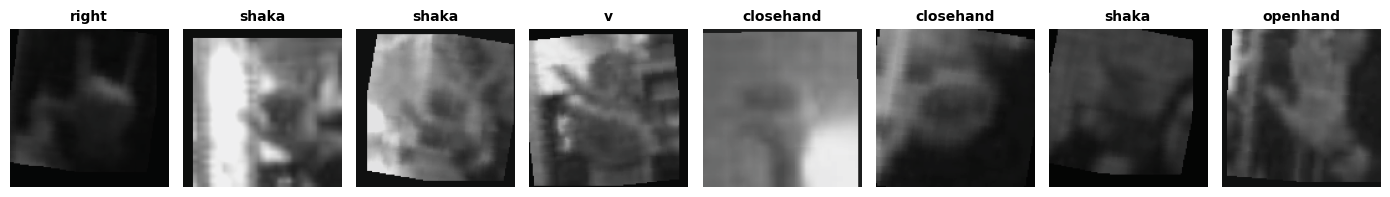

In [2]:
from src.dataset import get_dataloaders, denormalize, get_device
import matplotlib.pyplot as plt

device = get_device()
print(f"🚀 Urządzenie obliczeniowe: {device}")

# Pobranie DataLoaderów (img_size=128, batch_size=32)
train_loader, val_loader, class_names = get_dataloaders(img_size=128, batch_size=32)
print(f"🏷️ Klasy ({len(class_names)}): {class_names}")
print(f"📸 Próbki train: {len(train_loader.dataset)} | val: {len(val_loader.dataset)}")

# Podgląd losowych próbek po augmentacji (bezpieczne rotacje, kolor, bez odbijania left/right!)
images, labels = next(iter(train_loader))
plt.figure(figsize=(14, 4))
for i in range(min(8, len(images))):
    plt.subplot(1, 8, i + 1)
    plt.imshow(denormalize(images[i]))
    plt.title(class_names[labels[i]], fontsize=10, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 2. 📊 Uruchomienie TensorBoarda na żywo
Poniższa komórka uruchamia interaktywny dashboard, w którym na żywo pojawią się wykresy wszystkich Twoich eksperymentów.


In [3]:
%load_ext tensorboard
%tensorboard --logdir runs/gesture_cnn


## 3. 🧠 Eksperyment 1: `GestureCNN_v1` (Autorski model bazowy)
Architektura zdefiniowana w pliku `src/models/custom_cnn.py`:
- 4 bloki konwolucyjne z BatchNorm
- Global Average Pooling (chroni przed przeuczeniem przy małym zbiorze)
- Kompaktowa głowica Dense z Dropoutem


In [ ]:
from src.models import GestureCNN_v1, print_model_summary
from src.trainer import train_model

model_v1 = GestureCNN_v1(num_classes=len(class_names), base_filters=32)
print_model_summary(model_v1)

# Uruchomienie treningu (wyniki pojawią się na żywo w oknie TensorBoarda powyżej)
trained_v1 = train_model(
    model=model_v1,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=35,
    lr=0.01,
    experiment_name="exp1_custom_cnn_v1"
)


### 🎯 Ewaluacja Eksperymentu 1: Macierz pomyłek i analiza błędów


In [ ]:
from src.metrics import evaluate_model, show_misclassified_samples

# 1. Raport klasyfikacji i Macierz Pomyłek
evaluate_model(
    model=trained_v1, 
    val_loader=val_loader, 
    class_names=class_names, 
    title="Custom CNN v1",
    save_path="reports/confusion_matrix_v1.png"
)

# 2. Zdjęcia, na których model popełnił błąd (Error Analysis)
show_misclassified_samples(trained_v1, val_loader, class_names, max_images=8)


## 4. 🔬 Eksperyment 2: `GestureCNN_Residual` (Połączenia rezydualne / skip connections)
Architektura w `src/models/custom_cnn.py` wykorzystująca bloki `ResidualBlock` inspirowane ResNetem.
Po uruchomieniu przełącz się w TensorBoardzie, aby zobaczyć porównanie krzywych obu modeli!


In [ ]:
from src.models import GestureCNN_Residual

model_res = GestureCNN_Residual(num_classes=len(class_names), base_filters=32)
print_model_summary(model_res)

trained_res = train_model(
    model=model_res,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=35,
    lr=0.001,
    experiment_name="exp2_custom_residual"
)

evaluate_model(
    model=trained_res, 
    val_loader=val_loader, 
    class_names=class_names, 
    title="Custom CNN Residual",
    save_path="reports/confusion_matrix_residual.png"
)


## 5. 🥊 Eksperyment 3 (Baseline do pracy): `MobileNetV3-Small` (Transfer Learning)
W pracy inżynierskiej warto zestawić autorski model z popularnym standardem branżowym.  
Model zdefiniowany w `src/models/baselines.py` (pretrenowany na ImageNet ze zmienioną głowicą).


In [ ]:
from src.models import MobileNetV3Baseline

model_mobilenet = MobileNetV3Baseline(num_classes=len(class_names), pretrained=True)
print_model_summary(model_mobilenet)

trained_mobilenet = train_model(
    model=model_mobilenet,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=30,
    lr=0.0005,
    experiment_name="exp3_mobilenet_v3"
)

evaluate_model(
    model=trained_mobilenet, 
    val_loader=val_loader, 
    class_names=class_names, 
    title="MobileNetV3 Baseline",
    save_path="reports/confusion_matrix_mobilenet.png"
)


## 6. 🛠️ Jak tworzyć własne, nowe modele do eksperymentów?
1. Otwórz plik `src/models/custom_cnn.py`.
2. Dopisz swoją własną klasę, np. `class MyExperimentCNN(nn.Module): ...`
3. Zaimportuj ją w nowej komórce notatnika i puść trening:
```python
from src.models.custom_cnn import MyExperimentCNN

my_model = MyExperimentCNN(num_classes=8)
train_model(my_model, train_loader, val_loader, experiment_name="exp4_my_idea")
```
Dzięki `%autoreload 2` nie musisz restartować notatnika po edycji pliku `.py`!


## 7. 📦 Eksport wybranego modelu pod drona (TorchScript & ONNX)
Gdy wyłonisz najlepszy model z eksperymentów, wyeksportuj go jednym poleceniem:


In [ ]:
from src.export import export_model

# Eksportujemy model, który okazał się najlepszy (np. trained_v1 lub trained_res)
export_model(trained_v1, output_dir="weights", model_name="best_gesture_cnn")
